In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


##Clean List of the Games Dataset

In [3]:
import pandas as pd
import numpy as np

#Import Games Clean Dataset
df=pd.read_csv("games_clean(1).csv")
df.head()

,app_id,name,type,is_free,price,genres,release_date,review_score,total_positive,total_negative,rating_group,owners,owners_avg
0,1016360,PERISH,game,False,19.99,"Action, Indie",2023-02-02,Mostly Positive,228,64,Mixed (40-69%),"20,000 .. 50,000",35000.0
1,105600,Terraria,game,False,9.99,"Action, Adventure, Indie, RPG",2011-05-16,Overwhelmingly Positive,727750,19018,Positive (80%+),"20,000,000 .. 50,000,000",35000000.0
2,4412000,Zad Archery,game,False,6.99,"Action, Casual, Indie, RPG, Strategy",2026-09-01,Mostly Positive,248,72,Mostly Positive (70-79%),"0 .. 20,000",10000.0
3,1535560,Farmer Against Potatoes Idle,game,True,0.00,"Casual, Free To Play, Indie, RPG, Simulation",2024-09-05,Very Positive,4443,260,Positive (80%+),"0 .. 20,000",10000.0
4,1296400,Architect Life: A House Design Simulator,game,False,29.99,"Indie, Simulation",2025-06-19,Mixed,71,96,Mixed (40-69%),"0 .. 20,000",10000.0


## Clean Copy of the Reviews Dataset

In [12]:
import pandas as pd
import numpy as np

#Import Games Clean Dataset
df=pd.read_csv("reviews_clean(1).csv")
df.head()

,app_id,review_id,recommended,review_text,playtime_at_review,timestamp_created,votes_helpful
0,1016360,236957724,True,"I first played PERISH in 2023, and I instantly...",656,1791195785,0
1,1016360,236382445,True,Good Times!,102,1790575940,0
2,1016360,230720771,True,It was a fun mindless shooter/slasher to zoom ...,2469,1784335004,0
3,1016360,228579458,True,I'm not a fan of its Epic launcher needs :/\nB...,218,1782145848,2
4,1016360,227613635,False,https://youtu.be/Kmaex6Whd6M\n\nHighly depende...,17,1781064240,0


### Figure 1: Total Steam Reviews vs. Estimated Game Ownership

This scatter plot examines the relationship between the total number of Steam reviews and estimated game ownership. The graph shows a positive association, with games receiving more reviews generally having higher estimated ownership. Both axes use logarithmic scales to account for large differences in game popularity. These findings suggest that review volume may be a stronger indicator of an indie game's popularity than the percentage of positive reviews.

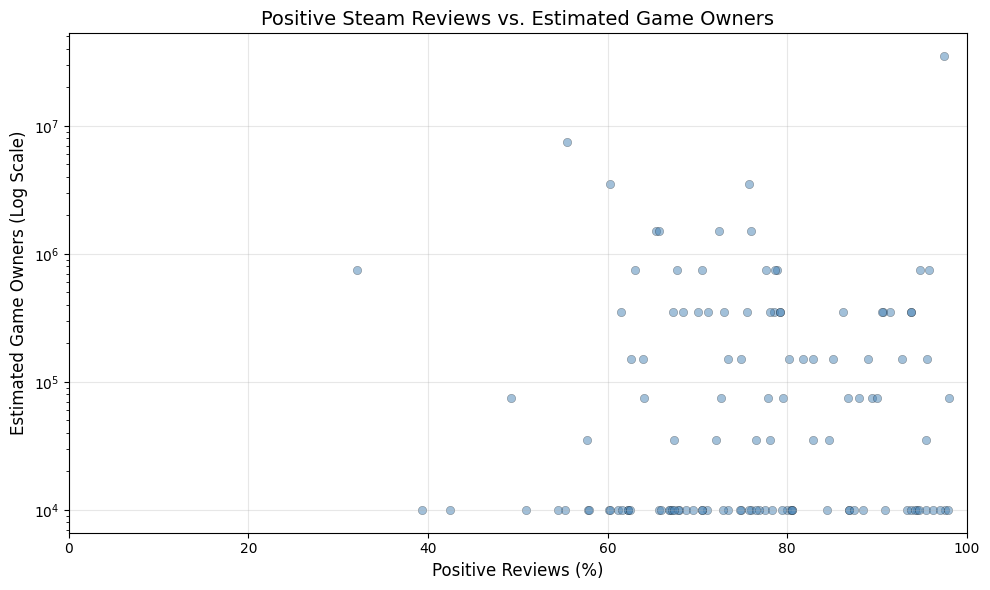

In [6]:

import pandas as pd
import matplotlib.pyplot as plt

# Load cleaned Steam games dataset
df = pd.read_csv("games_clean(1).csv")

# Calculate positive review percentage
df["positive_percent"] = (
    df["total_positive"] /
    (df["total_positive"] + df["total_negative"])
) * 100

# Remove missing values and zero ownership values
df = df.dropna(subset=["positive_percent", "owners_avg"])
df = df[df["owners_avg"] > 0]

# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    df["positive_percent"],
    df["owners_avg"],
    color="steelblue",
    alpha=0.5,
    edgecolors="black",
    linewidths=0.3
)

# Graph title and labels
plt.title(
    "Positive Steam Reviews vs. Estimated Game Owners",
    fontsize=14
)
plt.xlabel("Positive Reviews (%)", fontsize=12)
plt.ylabel("Estimated Game Owners (Log Scale)", fontsize=12)

# Improve readability
plt.yscale("log")
plt.xlim(0, 100)
plt.grid(True, alpha=0.3)

# Adjust layout
plt.tight_layout()

# Display graph
plt.show()


### Figure 2: Total Steam Reviews vs. Estimated Game Ownership

This scatter plot examines the relationship between the total number of Steam reviews and estimated game ownership. The graph displays a positive association, with games receiving more reviews generally having higher estimated ownership. Both axes use logarithmic scales to accommodate large differences in game popularity. These findings suggest that review volume may be a stronger indicator of an indie game's popularity than the percentage of positive reviews.



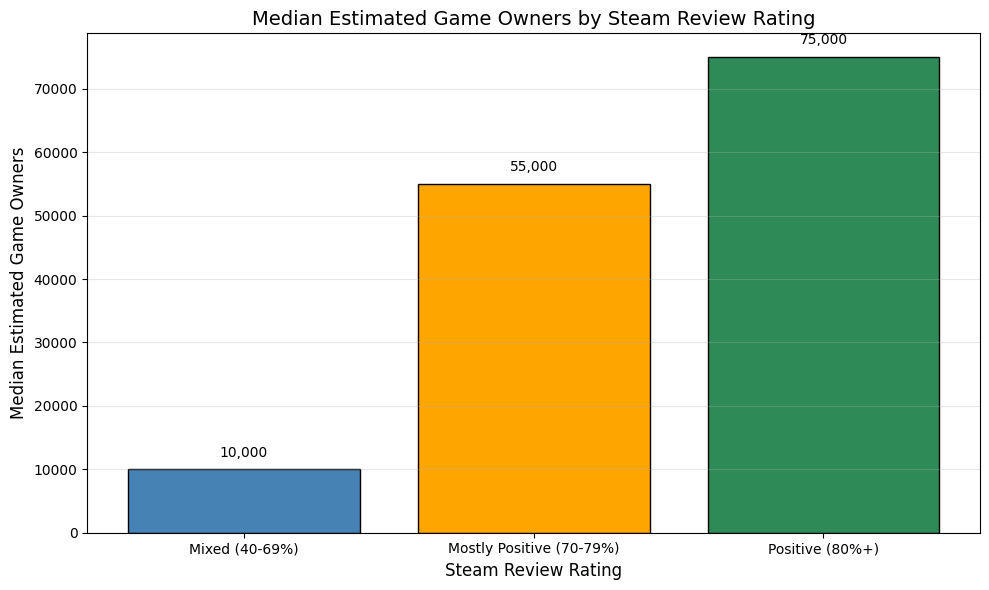

In [7]:

import pandas as pd
import matplotlib.pyplot as plt

# Load cleaned Steam games dataset
df = pd.read_csv("games_clean(1).csv")

# Select the three main review categories
categories = [
    "Mixed (40-69%)",
    "Mostly Positive (70-79%)",
    "Positive (80%+)"
]

# Calculate median estimated owners for each category
median_owners = (
    df.groupby("rating_group")["owners_avg"]
    .median()
    .reindex(categories)
)

# Create bar chart
plt.figure(figsize=(10, 6))

plt.bar(
    categories,
    median_owners,
    color=["steelblue", "orange", "seagreen"],
    edgecolor="black"
)

# Add values above each bar
for i, value in enumerate(median_owners):
    plt.text(
        i,
        value + 2000,
        f"{value:,.0f}",
        ha="center"
    )

# Graph title and labels
plt.title(
    "Median Estimated Game Owners by Steam Review Rating",
    fontsize=14
)
plt.xlabel("Steam Review Rating", fontsize=12)
plt.ylabel("Median Estimated Game Owners", fontsize=12)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()


### Figure 3: Total Steam Reviews vs. Estimated Game Ownership

This scatter plot examines the relationship between the total number of Steam reviews and estimated game ownership. The graph displays a positive association, with games receiving more reviews generally having higher estimated ownership. Both axes use logarithmic scales to accommodate large differences in game popularity. These findings suggest that review volume may be a stronger indicator of an indie game's popularity than the percentage of positive reviews. However, correlation does not establish that reviews directly cause increased ownership.


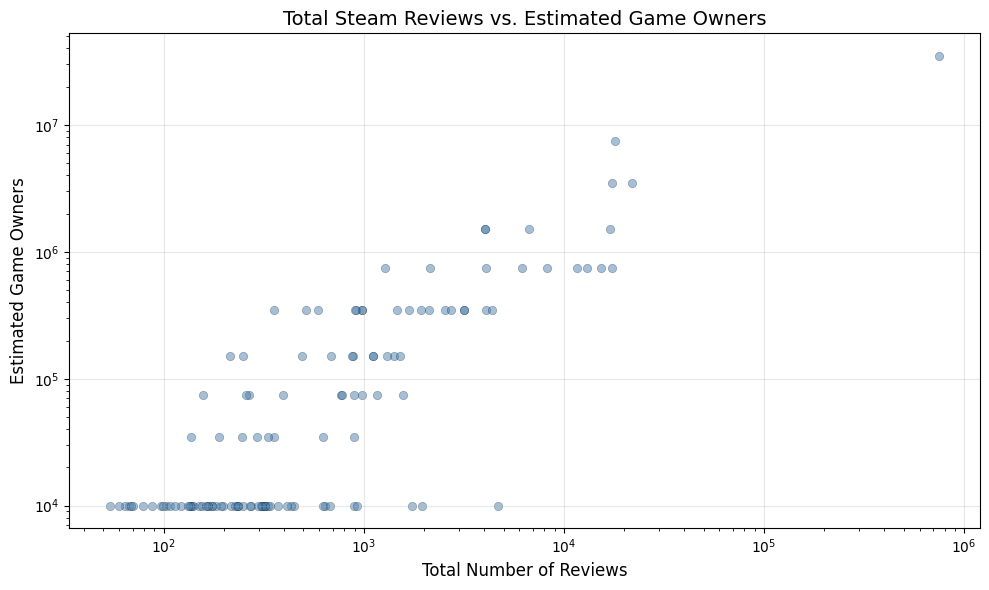

Spearman correlation: 0.780


In [8]:

import pandas as pd
import matplotlib.pyplot as plt

# Load cleaned Steam dataset
df = pd.read_csv("games_clean(1).csv")

# Calculate total number of reviews
df["total_reviews"] = (
    df["total_positive"] + df["total_negative"]
)

# Remove missing and zero values
df = df.dropna(subset=["total_reviews", "owners_avg"])
df = df[
    (df["total_reviews"] > 0) &
    (df["owners_avg"] > 0)
]

# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    df["total_reviews"],
    df["owners_avg"],
    color="steelblue",
    alpha=0.5,
    edgecolors="black",
    linewidths=0.3
)

# Titles and axis labels
plt.title(
    "Total Steam Reviews vs. Estimated Game Owners",
    fontsize=14
)
plt.xlabel("Total Number of Reviews", fontsize=12)
plt.ylabel("Estimated Game Owners", fontsize=12)

# Log scales to make smaller games visible
plt.xscale("log")
plt.yscale("log")

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

# Statistical analysis
correlation = df["total_reviews"].corr(
    df["owners_avg"],
    method="spearman"
)

print(f"Spearman correlation: {correlation:.3f}")


### Figure 4: Distribution of Positive Steam Review Percentages

This histogram illustrates the distribution of positive review percentages among the indie games in the dataset. Each bar represents a 10-percentage-point range, while the height indicates the number of games within that range. This visualization helps identify common review scores and examine how player satisfaction varies across the sampled games. It also provides context for understanding the relationship between review positivity and estimated game ownership.

Because the dataset was sampled across review-rating categories, the distribution should not be interpreted as representative of all indie games on Steam.


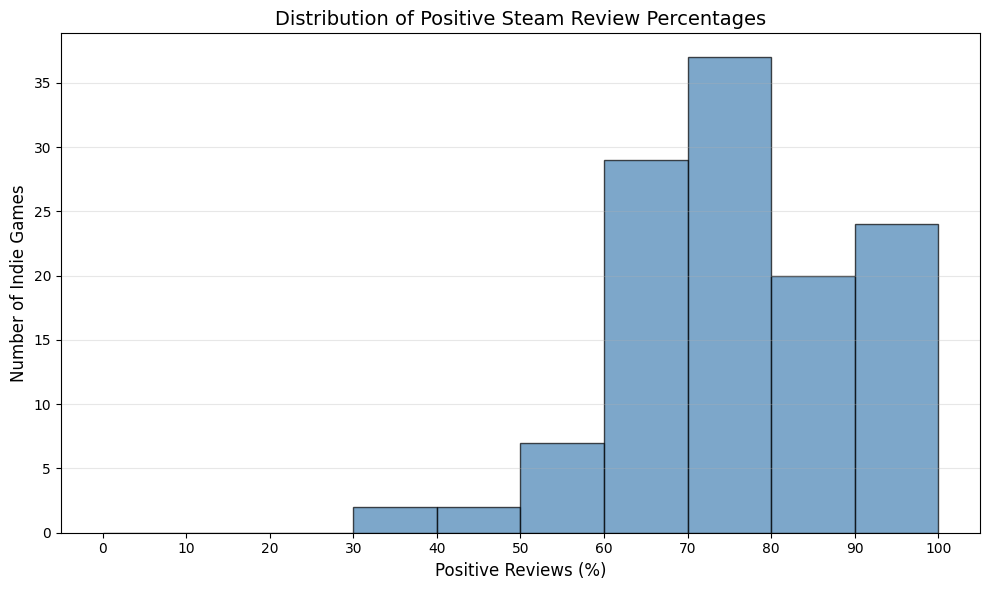

Mean: 75.88
Median: 75.98
Standard Deviation: 13.59


In [9]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load cleaned Steam games dataset
df = pd.read_csv("games_clean(1).csv")

# Calculate positive review percentage
df["positive_percent"] = (
    df["total_positive"] /
    (df["total_positive"] + df["total_negative"])
) * 100

# Remove missing values
df = df.dropna(subset=["positive_percent"])

# Create histogram
plt.figure(figsize=(10, 6))

plt.hist(
    df["positive_percent"],
    bins=np.arange(0, 110, 10),
    color="steelblue",
    edgecolor="black",
    alpha=0.7
)

# Add title and labels
plt.title(
    "Distribution of Positive Steam Review Percentages",
    fontsize=14
)
plt.xlabel("Positive Reviews (%)", fontsize=12)
plt.ylabel("Number of Indie Games", fontsize=12)

# Improve readability
plt.xticks(range(0, 101, 10))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Summary statistics
print("Mean:", round(df["positive_percent"].mean(), 2))
print("Median:", round(df["positive_percent"].median(), 2))
print("Standard Deviation:", round(df["positive_percent"].std(), 2))
